# TA-07 — Sistem Pengelolaan Persediaan Barang pada Minimarket Menggunakan Q-Learning

**Mata Praktikum:** Pembelajaran Mesin — Modul 07 Reinforcement Learning
**Nama / NIM:** _(isi)_  

Notebook ini melanjutkan rancangan **TP-07**. Isinya mengikuti langkah TA-07:

| Bagian | Isi |
|---|---|
| Langkah 1 | Lingkungan simulasi minimarket (State, Action, Reward dari TP-07) |
| Langkah 2 | Implementasi Q-Learning + ε-greedy (model *baseline* α = 0.8, γ = 0.9) |
| Langkah 3 | Kurva pembelajaran & analisis konvergensi |
| Langkah 4 | Ekstraksi, visualisasi, dan interpretasi kebijakan optimal |
| Langkah 5 | Eksperimen hiperparameter: Learning Rate (α) |
| Langkah 6 | Model final (perbaikan berdasarkan Langkah 5) & kesimpulan |

Seluruh kode hanya memakai **NumPy, Pandas, Matplotlib** (Python murni, tanpa Gymnasium), sehingga bisa langsung dijalankan di Jupyter atau Google Colab.

In [1]:
import os
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

pd.set_option("display.precision", 2)
np.set_printoptions(precision=2, suppress=True)
os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)
print("Library siap.")

Library siap.


## Langkah 1 — Persiapan Lingkungan (Environment Setup)

### Re-definisi S, A, R (dari TP-07)

| Elemen | Definisi |
|---|---|
| **Agen** | Sistem cerdas pengatur persediaan (manajer stok otomatis) |
| **Lingkungan** | Minimarket dengan persediaan satu jenis barang dan permintaan pelanggan yang berubah-ubah |
| **State (S)** | Stok {Rendah, Sedang, Tinggi} × Permintaan {Rendah, Sedang, Tinggi} = **9 state** |
| **Action (A)** | 0 = Pesan Sedikit, 1 = Pesan Banyak, 2 = Tidak Pesan → **3 aksi** |
| **Reward (R)** | **+10** kebutuhan pelanggan terpenuhi · **+5** persediaan ideal · **−5** stok habis · **−3** penumpukan barang |
| **Ukuran Q-Table** | 9 × 3 = 27 sel |

### Asumsi kuantitatif simulasi
Agar rancangan TP-07 dapat disimulasikan, kategori kualitatif diterjemahkan menjadi angka. Satuannya adalah unit atau karton, dan satu langkah sama dengan satu hari:

| Parameter | Nilai |
|---|---|
| Kapasitas rak + gudang | 20 unit (kelebihan dianggap penumpukan) |
| Kategori stok | Rendah 0–6, **Sedang 7–13 (ideal)**, Tinggi 14–20 |
| Jumlah pesanan | Sedikit = 5 unit, Banyak = 10 unit, Tidak = 0 (barang tiba di awal hari) |
| Permintaan harian | Rendah 2–4, Sedang 5–8, Tinggi 9–12 unit (acak seragam) |
| Perubahan tingkat permintaan | Rantai Markov: 60% tetap, sisanya berpindah ke tingkat lain |
| Episode | 30 hari (1 bulan operasional) |

**Urutan kejadian dalam satu hari:** agen mengamati state (kategori stok, tingkat permintaan) → memilih aksi → barang pesanan datang → pelanggan membeli → reward dihitung → state hari berikutnya.

**Aturan reward per hari:**
- +10 jika seluruh permintaan terlayani; −5 jika stok habis sebelum permintaan terpenuhi.
- +5 jika stok akhir hari berada di kategori *Sedang* (ideal).
- −3 jika stok akhir hari *Tinggi* atau gudang meluap (penumpukan).

Dengan demikian, reward harian maksimum adalah 15, dan reward maksimum per episode adalah 450.

In [ ]:
import numpy as np

STOCK_LABELS = ["Rendah", "Sedang", "Tinggi"]
DEMAND_LABELS = ["Rendah", "Sedang", "Tinggi"]
ACTION_LABELS = ["Pesan Sedikit", "Pesan Banyak", "Tidak Pesan"]
ACTION_SYMBOLS = ["S", "B", "-"]          # simbol singkat untuk peta kebijakan


class MinimarketInventoryEnv:
    """Simulasi persediaan satu jenis barang di minimarket selama satu periode (episode)."""

    # ---- parameter fisik minimarket (satuan: unit/karton) ----
    CAPACITY = 20                                 # kapasitas rak + gudang
    STOCK_BINS = [(0, 6), (7, 13), (14, 20)]      # batas kategori stok Rendah/Sedang/Tinggi
    ORDER_QTY = {0: 5, 1: 10, 2: 0}               # jumlah unit per aksi
    DEMAND_RANGE = {0: (2, 4), 1: (5, 8), 2: (9, 12)}   # jumlah permintaan per kategori
    # Peluang perubahan tingkat permintaan dari hari ke hari (baris = hari ini)
    DEMAND_TRANSITION = np.array([
        [0.6, 0.3, 0.1],
        [0.2, 0.6, 0.2],
        [0.1, 0.3, 0.6],
    ])

    # ---- reward sesuai TP-07 ----
    R_FULFILLED = 10
    R_IDEAL = 5
    R_STOCKOUT = -5
    R_OVERSTOCK = -3

    n_states = 9
    n_actions = 3

    def __init__(self, episode_length=30, seed=None):
        self.episode_length = episode_length
        self.rng = np.random.default_rng(seed)
        self.reset()

    # ---------- helper ----------
    @classmethod
    def stock_category(cls, units):
        for idx, (lo, hi) in enumerate(cls.STOCK_BINS):
            if lo <= units <= hi:
                return idx
        return 2

    @staticmethod
    def encode(stock_cat, demand_cat):
        """(stok, permintaan) -> indeks state 0..8  (state = stok*3 + permintaan)."""
        return stock_cat * 3 + demand_cat

    @staticmethod
    def decode(state):
        return divmod(state, 3)

    @staticmethod
    def state_label(state):
        s, d = divmod(state, 3)
        return f"Stok {STOCK_LABELS[s]} | Permintaan {DEMAND_LABELS[d]}"

    # ---------- API utama ----------
    def reset(self):
        self.day = 0
        self.stock = int(self.rng.integers(0, self.CAPACITY + 1))
        self.demand_cat = int(self.rng.integers(0, 3))
        self.state = self.encode(self.stock_category(self.stock), self.demand_cat)
        return self.state

    def step(self, action):
        """Menerima action -> mengembalikan (new_state, reward, done, info)."""
        assert action in (0, 1, 2), "Aksi harus 0, 1, atau 2"

        # 1) Barang pesanan datang di awal hari
        incoming = self.ORDER_QTY[action]
        stock_after_order = self.stock + incoming
        overflow = max(0, stock_after_order - self.CAPACITY)
        stock_after_order = min(stock_after_order, self.CAPACITY)

        # 2) Pelanggan datang: jumlah permintaan acak sesuai kategori hari ini
        lo, hi = self.DEMAND_RANGE[self.demand_cat]
        demand = int(self.rng.integers(lo, hi + 1))
        sold = min(stock_after_order, demand)
        self.stock = stock_after_order - sold
        end_cat = self.stock_category(self.stock)

        # 3) Hitung reward (rancangan TP-07)
        reward = 0
        fulfilled = sold == demand
        if fulfilled:
            reward += self.R_FULFILLED
        else:
            reward += self.R_STOCKOUT            # stok habis sebelum permintaan terpenuhi
        if end_cat == 1:
            reward += self.R_IDEAL               # persediaan ideal
        if end_cat == 2 or overflow > 0:
            reward += self.R_OVERSTOCK           # penumpukan barang

        # 4) Permintaan hari berikutnya & state baru
        self.demand_cat = int(self.rng.choice(3, p=self.DEMAND_TRANSITION[self.demand_cat]))
        self.state = self.encode(end_cat, self.demand_cat)
        self.day += 1
        done = self.day >= self.episode_length

        info = {"demand": demand, "sold": sold, "lost_sales": demand - sold,
                "order": incoming, "overflow": overflow, "stock_units": self.stock,
                "fulfilled": fulfilled}
        return self.state, reward, done, info

In [3]:
# Uji cepat lingkungan: 7 hari dengan aksi acak
env_test = MinimarketInventoryEnv(seed=0)
state = env_test.reset()
rng_test = np.random.default_rng(0)
log = []
for _ in range(7):
    action = int(rng_test.integers(3))
    new_state, reward, done, info = env_test.step(action)
    log.append({"Hari": env_test.day, "State awal": MinimarketInventoryEnv.state_label(state),
                "Aksi": ACTION_LABELS[action], "Permintaan": info["demand"], "Terjual": info["sold"],
                "Stok akhir": info["stock_units"], "Reward": reward,
                "State baru": MinimarketInventoryEnv.state_label(new_state), "Done": done})
    state = new_state
display(pd.DataFrame(log))

,Hari,State awal,Aksi,Permintaan,Terjual,Stok akhir,Reward,State baru,Done
0,1,Stok Sedang | Permintaan Rendah,Tidak Pesan,2,2,8,15,Stok Sedang | Permintaan Rendah,False
1,2,Stok Sedang | Permintaan Rendah,Pesan Banyak,2,2,16,7,Stok Tinggi | Permintaan Sedang,False
2,3,Stok Tinggi | Permintaan Sedang,Pesan Banyak,7,7,13,12,Stok Sedang | Permintaan Sedang,False
3,4,Stok Sedang | Permintaan Sedang,Pesan Sedikit,8,8,10,15,Stok Sedang | Permintaan Sedang,False
4,5,Stok Sedang | Permintaan Sedang,Pesan Sedikit,7,7,8,15,Stok Sedang | Permintaan Tinggi,False
5,6,Stok Sedang | Permintaan Tinggi,Pesan Sedikit,11,11,2,10,Stok Rendah | Permintaan Tinggi,False
6,7,Stok Rendah | Permintaan Tinggi,Pesan Sedikit,11,7,0,-5,Stok Rendah | Permintaan Tinggi,False


## Langkah 2 — Implementasi Q-Learning

Q-Table berukuran **9 × 3** diinisialisasi dengan nol. Q-Table diperbarui dengan Persamaan Bellman:

$$Q(s,a) \leftarrow (1-\alpha)\,Q(s,a) + \alpha\left[r + \gamma \max_{a'} Q(s',a')\right]$$

Aksi dipilih dengan **ε-greedy**. Nilai ε meluruh secara eksponensial: $\epsilon = \epsilon_{min} + (\epsilon_{max}-\epsilon_{min})e^{-\text{decay}\cdot episode}$.

> Catatan perbaikan dari kode tutorial modul: (1) variabel `max_epsilon` didefinisikan; (2) total reward per episode dicatat ke dalam list; (3) pada hari terakhir (terminal) target Q hanya berisi reward, tanpa nilai masa depan.

In [ ]:
import numpy as np


def train_q_learning(alpha=0.8, gamma=0.9, episodes=2000, epsilon=1.0, min_epsilon=0.01,
                     max_epsilon=1.0, decay_rate=0.005, episode_length=30, seed=42):
    """
    Melatih agen Q-Learning pada MinimarketInventoryEnv.

    Return
    ------
    q_table : ndarray (9, 3)
    history : dict berisi
        rewards  - total reward tiap episode
        epsilons - nilai epsilon yang dipakai tiap episode
        q_mean   - rata-rata max_a Q(s,a) di akhir tiap episode (memantau pertumbuhan nilai Q)
        q_change - total |perubahan Q| dalam satu episode (memantau stabilitas Q-Table)
        visits   - jumlah kunjungan tiap state selama pelatihan
    """
    env = MinimarketInventoryEnv(episode_length=episode_length, seed=seed)
    rng = np.random.default_rng(seed)
    q_table = np.zeros((env.n_states, env.n_actions))
    history = {"rewards": [], "epsilons": [], "q_mean": [], "q_change": [],
               "visits": np.zeros(env.n_states, dtype=int)}

    for episode in range(episodes):
        state = env.reset()
        total_reward, total_change, done = 0, 0.0, False

        while not done:
            # 1. Pilih aksi dengan epsilon-greedy
            if rng.uniform() < epsilon:
                action = int(rng.integers(env.n_actions))          # eksplorasi
            else:
                action = int(np.argmax(q_table[state]))           # eksploitasi

            # 2. Jalankan aksi di lingkungan
            new_state, reward, done, _ = env.step(action)

            # 3. Update Q-Table (Persamaan Bellman)
            #    Q(s,a) <- (1-alpha)Q(s,a) + alpha[r + gamma * max_a' Q(s',a')]
            #    Pada hari terakhir (terminal) tidak ada nilai masa depan.
            target = reward if done else reward + gamma * np.max(q_table[new_state])
            old_q = q_table[state, action]
            q_table[state, action] = (1 - alpha) * old_q + alpha * target

            total_change += abs(q_table[state, action] - old_q)
            history["visits"][state] += 1
            total_reward += reward
            state = new_state

        history["rewards"].append(total_reward)
        history["epsilons"].append(epsilon)
        history["q_mean"].append(q_table.max(axis=1).mean())
        history["q_change"].append(total_change)

        # 4. Peluruhan epsilon (eksplorasi berkurang seiring waktu)
        epsilon = min_epsilon + (max_epsilon - min_epsilon) * np.exp(-decay_rate * episode)

    return q_table, history


def evaluate_policy(policy_fn, n_episodes=500, episode_length=30, seed=2024):
    """Menjalankan kebijakan tanpa eksplorasi (greedy) dan merangkum performanya."""
    env = MinimarketInventoryEnv(episode_length=episode_length, seed=seed)
    totals, days = [], 0
    counts = {"fulfilled": 0, "stockout": 0, "ideal": 0, "overstock": 0, "lost": 0, "demand": 0}
    for _ in range(n_episodes):
        state, done, total = env.reset(), False, 0
        while not done:
            state, r, done, info = env.step(policy_fn(state))
            total += r
            days += 1
            cat = env.stock_category(info["stock_units"])
            counts["fulfilled"] += info["fulfilled"]
            counts["stockout"] += not info["fulfilled"]
            counts["ideal"] += cat == 1
            counts["overstock"] += (cat == 2) or info["overflow"] > 0
            counts["lost"] += info["lost_sales"]
            counts["demand"] += info["demand"]
        totals.append(total)
    return {
        "Rata-rata reward/episode": np.mean(totals),
        "Service level (%)": 100 * counts["fulfilled"] / days,
        "Hari stok habis (%)": 100 * counts["stockout"] / days,
        "Hari stok ideal (%)": 100 * counts["ideal"] / days,
        "Hari penumpukan (%)": 100 * counts["overstock"] / days,
        "Penjualan hilang (%)": 100 * counts["lost"] / counts["demand"],
    }

In [5]:
# Hiperparameter baseline (sesuai saran TA-07)
BASE = dict(alpha=0.8, gamma=0.9, episodes=2000, epsilon=1.0, min_epsilon=0.01,
            max_epsilon=1.0, decay_rate=0.005, episode_length=30, seed=42)

q_base, hist_base = train_q_learning(**BASE)

state_index = [MinimarketInventoryEnv.state_label(s) for s in range(9)]
q_base_df = pd.DataFrame(q_base, index=state_index, columns=ACTION_LABELS)
q_base_df["Aksi terbaik"] = [ACTION_LABELS[a] for a in q_base.argmax(axis=1)]
q_base_df["Kunjungan"] = hist_base["visits"]
print("Q-Table model baseline setelah 2000 episode:")
display(q_base_df)

Q-Table model baseline setelah 2000 episode:


,Pesan Sedikit,Pesan Banyak,Tidak Pesan,Aksi terbaik,Kunjungan
Stok Rendah | Permintaan Rendah,16.22,98.01,10.12,Pesan Banyak,5878
Stok Rendah | Permintaan Sedang,21.40,76.41,20.83,Pesan Banyak,11594
Stok Rendah | Permintaan Tinggi,19.99,95.03,2.21,Pesan Banyak,10098
Stok Sedang | Permintaan Rendah,25.75,91.12,47.54,Pesan Banyak,7674
Stok Sedang | Permintaan Sedang,105.79,24.43,78.75,Pesan Sedikit,11318
Stok Sedang | Permintaan Tinggi,19.14,54.61,25.57,Pesan Banyak,6211
Stok Tinggi | Permintaan Rendah,89.72,20.92,33.24,Pesan Sedikit,3525
Stok Tinggi | Permintaan Sedang,15.75,24.24,30.79,Tidak Pesan,2647
Stok Tinggi | Permintaan Tinggi,110.02,25.25,26.49,Pesan Sedikit,1055


## Langkah 3 — Analisis Konvergensi dan Eksplorasi

ε turun di bawah 0.05 pada episode ke-643


,Baseline
Level akhir (rata-rata MA 300 ep terakhir),299.9
Episode pertama mencapai 95% level akhir,717
Episode sejak MA selalu >= 95% level akhir,1883
Std reward 200 episode awal,78.0
Std reward 500 episode akhir,70.3
Reward min / maks 100 episode awal,-15 / 366


MA-100 pada episode tertentu:


,99,199,299,499,699,999,1499,1999
MA-100,194.7,242.8,262.4,251.1,274.3,324.9,351.7,330.5


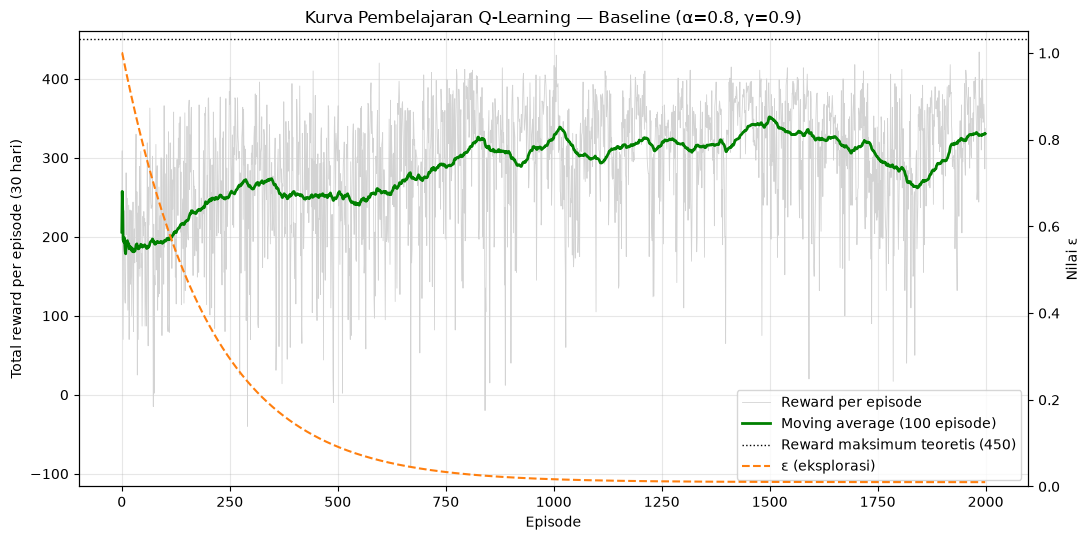

In [6]:
def convergence_stats(rewards, window=100, tail=300, tol=0.95):
    ma = pd.Series(rewards).rolling(window, min_periods=1).mean()
    final_level = ma.iloc[-tail:].mean()
    first_hit = int(np.argmax(ma.values >= tol * final_level))
    stays = next(i for i in range(len(ma)) if (ma.iloc[i:] >= tol * final_level).all())
    r = pd.Series(rewards)
    return ma, {"Level akhir (rata-rata MA 300 ep terakhir)": round(final_level, 1),
                "Episode pertama mencapai 95% level akhir": first_hit,
                "Episode sejak MA selalu >= 95% level akhir": stays,
                "Std reward 200 episode awal": round(r[:200].std(), 1),
                "Std reward 500 episode akhir": round(r[-500:].std(), 1),
                "Reward min / maks 100 episode awal": f"{r[:100].min()} / {r[:100].max()}"}


def plot_learning_curve(hist, title, path, window=100):
    ma, _ = convergence_stats(hist["rewards"], window)
    fig, ax1 = plt.subplots(figsize=(11, 5.5))
    ax1.plot(hist["rewards"], color="lightgray", lw=0.6, label="Reward per episode")
    ax1.plot(ma, color="green", lw=2, label=f"Moving average ({window} episode)")
    ax1.axhline(450, color="black", ls=":", lw=1, label="Reward maksimum teoretis (450)")
    ax1.set_xlabel("Episode"); ax1.set_ylabel("Total reward per episode (30 hari)")
    ax2 = ax1.twinx()
    ax2.plot(hist["epsilons"], color="tab:orange", ls="--", lw=1.5, label="ε (eksplorasi)")
    ax2.set_ylabel("Nilai ε"); ax2.set_ylim(0, 1.05)
    h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
    ax1.legend(h1 + h2, l1 + l2, loc="lower right")
    ax1.set_title(title); ax1.grid(True, alpha=0.3)
    fig.tight_layout(); fig.savefig(path, dpi=150)
    return ma

ma_base = plot_learning_curve(hist_base, "Kurva Pembelajaran Q-Learning — Baseline (α=0.8, γ=0.9)",
                              "figures/kurva_pembelajaran_baseline.png")
_, stats_base = convergence_stats(hist_base["rewards"])
eps_005 = int(np.argmax(np.array(hist_base["epsilons"]) < 0.05))
print(f"ε turun di bawah 0.05 pada episode ke-{eps_005}")
display(pd.Series(stats_base, name="Baseline").to_frame())
print("MA-100 pada episode tertentu:")
display(ma_base.iloc[[99, 199, 299, 499, 699, 999, 1499, 1999]].round(1).to_frame("MA-100").T)

### Analisis Kurva Pembelajaran (Baseline α = 0.8)

Kurva dapat dibagi menjadi tiga fase:

| Fase | Episode | Karakteristik grafik | Interpretasi |
|---|---|---|---|
| Eksplorasi intens | 0 – ±150 | MA sekitar 190–200. Reward per episode sangat lebar, dari **−15 sampai 366** | ε masih ≈ 1, sehingga agen memesan secara acak. Stok sering habis (−5) atau menumpuk (−3). Fluktuasi besar ini adalah ciri trial-and-error. Sebagai pembanding, kebijakan acak murni rata-rata hanya meraih ±165. |
| Pembelajaran | ±150 – ±1000 | MA naik dari ±195 ke ±325, tetapi sempat **stagnan di ±250 pada episode 300–600** | ε turun di bawah 0,05 pada episode ke-643, sehingga agen mulai mengeksploitasi Q-Table. Stagnasi menunjukkan Q-Table belum stabil: aksi terbaik di beberapa state masih berganti-ganti. |
| "Plateau" | > ±1000 | MA berada di 300–350, tetapi masih naik-turun (misalnya turun ke ±265 sekitar episode 1830) | Agen sudah hampir tidak bereksplorasi (ε ≈ 0,01), tetapi kurva **tidak benar-benar datar**. |

**Pada episode berapa konvergen?** MA-100 pertama kali mencapai 95% level akhirnya pada **episode ke-717**. Namun MA baru *selalu* berada di atas batas tersebut sejak **episode ke-1883**. Jadi model baseline hanya mencapai *plateau semu* di sekitar episode 700–1000, bukan konvergensi yang stabil.

**Mengapa masih berfluktuasi?** Standar deviasi reward pada 500 episode terakhir (**70,3**) hampir sama dengan 200 episode awal (**78,0**), padahal eksplorasi sudah hampir nol. Penyebabnya adalah **lingkungan stokastik**: jumlah permintaan harian acak. Dengan α = 0,8, setiap pembaruan menggantikan 80% nilai Q lama dengan *satu sampel* terbaru. Satu hari "sial", misalnya permintaan tinggi tak terduga, langsung menjatuhkan nilai Q suatu aksi, sehingga aksi terbaik berubah. Dugaan ini diuji secara khusus pada Langkah 5.

Level akhir **±300** masih jauh dari maksimum teoretis 450. Akan tetapi, nilai 450 praktis tidak mungkin dicapai karena stok akhir tidak selalu bisa dijaga di kategori ideal. Acuan yang lebih realistis adalah kebijakan terbaik hasil pencarian exhaustive pada Langkah 4, yaitu ±395.

## Langkah 4 — Analisis dan Interpretasi Kebijakan (Policy)

Kebijakan optimal diambil dengan $\pi(s) = \arg\max_a Q(s,a)$. Kebijakan divisualisasikan sebagai **grid 3×3**: baris adalah kategori stok, kolom adalah tingkat permintaan, dan warna menunjukkan aksi. Setiap sel juga memuat selisih Q antara aksi terbaik dan aksi terbaik kedua (Δ), yaitu ukuran seberapa "yakin" agen, serta jumlah kunjungan state selama pelatihan.

,State,Aksi,Kode
0,Stok Rendah | Permintaan Rendah,Pesan Banyak,B
1,Stok Rendah | Permintaan Sedang,Pesan Banyak,B
2,Stok Rendah | Permintaan Tinggi,Pesan Banyak,B
3,Stok Sedang | Permintaan Rendah,Pesan Banyak,B
4,Stok Sedang | Permintaan Sedang,Pesan Sedikit,S
5,Stok Sedang | Permintaan Tinggi,Pesan Banyak,B
6,Stok Tinggi | Permintaan Rendah,Pesan Sedikit,S
7,Stok Tinggi | Permintaan Sedang,Tidak Pesan,-
8,Stok Tinggi | Permintaan Tinggi,Pesan Sedikit,S


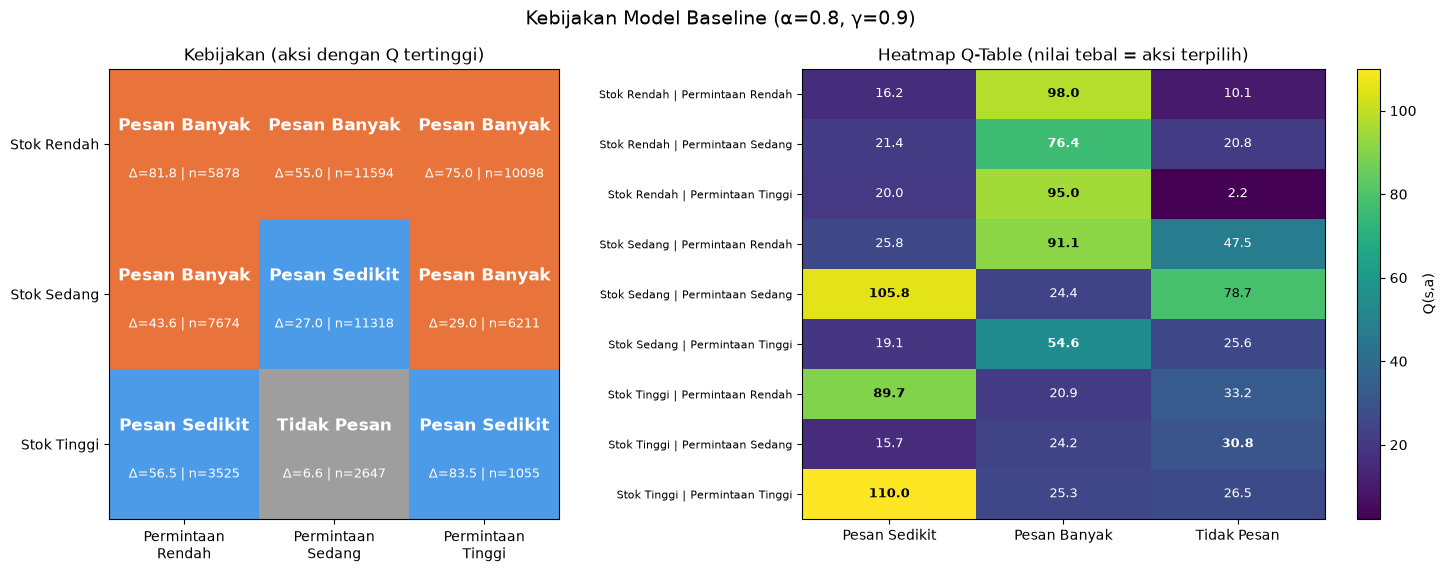

In [7]:
POLICY_COLORS = ListedColormap(["#4C9BE8", "#E8743B", "#9E9E9E"])   # Sedikit, Banyak, Tidak

def plot_policy(q, visits, title, path):
    pol = q.argmax(axis=1).reshape(3, 3)
    srt = np.sort(q, axis=1)
    gap = (srt[:, -1] - srt[:, -2]).reshape(3, 3)
    fig, axes = plt.subplots(1, 2, figsize=(15, 5.8), gridspec_kw={"width_ratios": [1, 1.25]})
    ax = axes[0]
    ax.imshow(pol, cmap=POLICY_COLORS, vmin=0, vmax=2)
    for i in range(3):
        for j in range(3):
            ax.text(j, i - 0.12, ACTION_LABELS[pol[i, j]], ha="center", va="center", color="white",
                    fontsize=12, fontweight="bold")
            ax.text(j, i + 0.2, f"Δ={gap[i, j]:.1f} | n={visits[i*3+j]}", ha="center", va="center",
                    color="white", fontsize=9)
    ax.set_xticks(range(3)); ax.set_xticklabels([f"Permintaan\n{d}" for d in DEMAND_LABELS])
    ax.set_yticks(range(3)); ax.set_yticklabels([f"Stok {s}" for s in STOCK_LABELS])
    ax.set_title("Kebijakan (aksi dengan Q tertinggi)")
    ax = axes[1]
    im = ax.imshow(q, cmap="viridis", aspect="auto")
    for s in range(9):
        for a in range(3):
            ax.text(a, s, f"{q[s, a]:.1f}", ha="center", va="center",
                    color="white" if q[s, a] < q.max() * 0.7 else "black",
                    fontweight="bold" if a == q[s].argmax() else "normal", fontsize=9)
    ax.set_xticks(range(3)); ax.set_xticklabels(ACTION_LABELS)
    ax.set_yticks(range(9)); ax.set_yticklabels([MinimarketInventoryEnv.state_label(s) for s in range(9)], fontsize=8)
    ax.set_title("Heatmap Q-Table (nilai tebal = aksi terpilih)")
    fig.colorbar(im, ax=ax, label="Q(s,a)")
    fig.suptitle(title, fontsize=14); fig.tight_layout(); fig.savefig(path, dpi=150)


def policy_table(q):
    return pd.DataFrame({"State": [MinimarketInventoryEnv.state_label(s) for s in range(9)],
                         "Aksi": [ACTION_LABELS[a] for a in q.argmax(axis=1)],
                         "Kode": [ACTION_SYMBOLS[a] for a in q.argmax(axis=1)]})

plot_policy(q_base, hist_base["visits"], "Kebijakan Model Baseline (α=0.8, γ=0.9)", "figures/kebijakan_baseline.png")
display(policy_table(q_base))

### Validasi: kebijakan acuan dengan pencarian exhaustive
State space yang kecil memungkinkan kita mengevaluasi **seluruh 3⁹ = 19.683 kebijakan deterministik** pada skenario acak yang sama (*common random numbers*). Hasilnya menjadi acuan "optimum" untuk menilai kebijakan hasil Q-Learning. Cara ini hanya mungkin karena state space kecil, sehingga sekaligus menunjukkan *curse of dimensionality*: dengan 20 state saja, jumlah kebijakan sudah 3²⁰ ≈ 3,5 miliar.

In [ ]:
def brute_force(n_episodes=300, seed=7):
    rng = np.random.default_rng(seed)
    T = 30
    policies = np.array(list(itertools.product(range(3), repeat=9)), dtype=np.int8)   # (P, 9)
    P = len(policies)
    # skenario acak bersama
    stock0 = rng.integers(0, MinimarketInventoryEnv.CAPACITY + 1, n_episodes)
    dcat = np.zeros((n_episodes, T + 1), dtype=int)
    dcat[:, 0] = rng.integers(0, 3, n_episodes)
    u = rng.random((n_episodes, T))
    cum = MinimarketInventoryEnv.DEMAND_TRANSITION.cumsum(axis=1)
    for t in range(T):
        dcat[:, t + 1] = (u[:, t][:, None] > cum[dcat[:, t]]).sum(axis=1)
    lo = np.array([v[0] for v in MinimarketInventoryEnv.DEMAND_RANGE.values()])
    hi = np.array([v[1] for v in MinimarketInventoryEnv.DEMAND_RANGE.values()])
    dem = (lo[dcat[:, :T]] + np.floor(rng.random((n_episodes, T)) * (hi - lo + 1)[dcat[:, :T]])).astype(int)

    def cat(x):
        return np.where(x <= 6, 0, np.where(x <= 13, 1, 2))

    order = np.array([MinimarketInventoryEnv.ORDER_QTY[a] for a in range(3)])
    stock = np.broadcast_to(stock0, (P, n_episodes)).copy()
    total = np.zeros((P, n_episodes))
    for t in range(T):
        state = cat(stock) * 3 + dcat[:, t][None, :]
        act = policies[np.arange(P)[:, None], state]
        s2 = stock + order[act]
        overflow = s2 > MinimarketInventoryEnv.CAPACITY
        s2 = np.minimum(s2, MinimarketInventoryEnv.CAPACITY)
        sold = np.minimum(s2, dem[:, t][None, :])
        full = sold == dem[:, t][None, :]
        stock = s2 - sold
        c = cat(stock)
        total += np.where(full, MinimarketInventoryEnv.R_FULFILLED, MinimarketInventoryEnv.R_STOCKOUT) + (c == 1) * MinimarketInventoryEnv.R_IDEAL \
                 + ((c == 2) | overflow) * MinimarketInventoryEnv.R_OVERSTOCK
    mean = total.mean(axis=1)
    order_idx = np.argsort(-mean)
    return policies, mean, order_idx



pol_all, mean_all, idx_all = brute_force()
top = pd.DataFrame({"Kebijakan (state 0–8)": ["".join(ACTION_SYMBOLS[a] for a in pol_all[i]) for i in idx_all[:8]],
                    "Rata-rata reward/episode": mean_all[idx_all[:8]].round(1)})
print("Kode: S = Pesan Sedikit, B = Pesan Banyak, - = Tidak Pesan; urutan state 0..8 seperti tabel kebijakan.")
display(top)
ref_policy = pol_all[idx_all[0]]
def policy_rank(q):
    pid = np.where((pol_all == q.argmax(1)).all(axis=1))[0][0]
    return int(np.where(idx_all == pid)[0][0]) + 1, mean_all[pid]

rank_base, score_base = policy_rank(q_base)
print("Kebijakan acuan terbaik:", "".join(ACTION_SYMBOLS[a] for a in ref_policy), f"({mean_all[idx_all[0]]:.1f})")
print(f"Kebijakan Q-baseline  : {''.join(ACTION_SYMBOLS[a] for a in q_base.argmax(1))} "
      f"({score_base:.1f}) -> peringkat {rank_base} dari {len(pol_all)}")

Kode: S = Pesan Sedikit, B = Pesan Banyak, - = Tidak Pesan; urutan state 0..8 seperti tabel kebijakan.


,Kebijakan (state 0–8),Rata-rata reward/episode
0,SBBSSB--S,394.6
1,BBBSSB--S,394.5
2,SBBSSB--B,394.3
3,BBBSSB--B,394.0
4,SBBSSB-SS,393.4
5,BBBSSB-SS,393.4
6,SBBSSB---,393.0
7,SBBSSB-SB,392.9


Kebijakan acuan terbaik: SBBSSB--S (394.6)
Kebijakan Q-baseline  : BBBBSBS-S (351.8) -> peringkat 277 dari 19683


In [9]:
rng_rand = np.random.default_rng(0)
candidates = {
    "Q-Learning baseline (α=0.8)": lambda s: int(np.argmax(q_base[s])),
    "Acuan exhaustive (terbaik)": lambda s: int(ref_policy[s]),
    "Acak": lambda s: int(rng_rand.integers(3)),
    "Selalu Pesan Sedikit": lambda s: 0,
    "Selalu Pesan Banyak": lambda s: 1,
    "Tidak Pernah Pesan": lambda s: 2,
}
eval_base = pd.DataFrame({k: evaluate_policy(f, n_episodes=500) for k, f in candidates.items()}).T.round(1)
print("Evaluasi greedy (ε = 0) pada 500 episode uji dengan seed berbeda dari pelatihan:")
display(eval_base)

Evaluasi greedy (ε = 0) pada 500 episode uji dengan seed berbeda dari pelatihan:


,Rata-rata reward/episode,Service level (%),Hari stok habis (%),Hari stok ideal (%),Hari penumpukan (%),Penjualan hilang (%)
Q-Learning baseline (α=0.8),352.7,99.7,0.3,54.4,30.8,0.1
Acuan exhaustive (terbaik),395.5,99.7,0.3,69.9,8.9,0.1
Acak,163.5,64.7,35.3,22.3,12.1,26.7
Selalu Pesan Sedikit,135.5,59.4,40.6,16.5,7.4,22.6
Selalu Pesan Banyak,305.1,99.8,0.2,49.0,75.1,0.0
Tidak Pernah Pesan,-128.9,4.3,95.7,1.4,0.3,95.1


### Interpretasi Kebijakan Baseline

Kebijakan baseline (`BBBBSBS-S`) dibandingkan dengan acuan exhaustive (`SBBSSB--S`):

| State | Baseline | Acuan | Penilaian |
|---|---|---|---|
| Stok Rendah, semua tingkat permintaan | Pesan Banyak | Banyak/Sedikit | ✅ **Logis.** Stok 0–6 tidak cukup untuk permintaan berikutnya, sehingga agen mengisi ulang dalam jumlah besar. Selisih Q sangat besar (Δ = 55–82), jadi agen sangat yakin. Untuk Rendah–Rendah, Sedikit dan Banyak hampir setara (394,6 vs 394,5). |
| Stok Sedang – Permintaan Sedang | Pesan Sedikit | Pesan Sedikit | ✅ Stok 7–13 + 5 − (5–8) tetap di zona ideal (+15/hari). |
| Stok Sedang – Permintaan Tinggi | Pesan Banyak | Pesan Banyak | ✅ Permintaan 9–12 akan menghabiskan stok jika tidak diisi besar. |
| Stok Tinggi – Permintaan Sedang/Tinggi | Tidak Pesan / Sedikit | sama | ✅ Sama dengan acuan. |
| **Stok Sedang – Permintaan Rendah** | **Pesan Banyak** | Pesan Sedikit | ❌ Stok 7–13 + 10 lalu terjual hanya 2–4, sehingga stok akhir 13–18 hampir selalu **menumpuk (−3)**. |
| **Stok Tinggi – Permintaan Rendah** | **Pesan Sedikit** | Tidak Pesan | ❌ Stok 14–20 + 5 hampir pasti **meluap** dari kapasitas gudang. |

**Kesimpulan:** 6 dari 9 aksi sudah logis, dan alur berpikir agen secara umum benar: *isi ulang besar saat stok rendah, pertahankan saat sedang, tahan saat tinggi*. Namun, dua kesalahan di state yang sering muncul menyebabkan **penumpukan pada 30,8% hari**, sedangkan kebijakan acuan hanya 8,9%. Akibatnya, reward rata-rata baseline hanya **352,7** dibanding acuan **395,5**, atau peringkat 277 dari 19.683 kebijakan.

Heatmap Q-Table juga menunjukkan gejala ketidakstabilan. Nilai Q antar-aksi sangat timpang tanpa pola yang masuk akal: di Stok Rendah–Permintaan Tinggi, Q(Banyak) = 95 tetapi Q(Tidak Pesan) = 2,2, dan Q(Sedikit) di Stok Tinggi–Permintaan Tinggi = 110. Pola seperti ini merupakan jejak beberapa sampel terakhir, bukan nilai harapan jangka panjang.

**Keterbatasan rancangan state.** Kategori *Rendah* mencakup stok 0 sampai 6 unit. Agen tidak dapat membedakan stok 0 dan 6, padahal keputusan terbaiknya bisa berbeda. Ketidakpastian ini (*state aliasing*) ikut menambah *noise* pada Q-Table.

## Langkah 5 — Eksperimen Hiperparameter: Learning Rate (α)

**Skenario:** hanya α yang diubah, sedangkan hiperparameter lain tetap (γ = 0.9, decay ε = 0.005, 2000 episode).
- **Default (tinggi): α = 0.8**
- **Ekstrem (sangat rendah): α = 0.01**
- Pembanding tambahan (opsional): α = 0.1

Agar kesimpulan tidak bergantung pada keberuntungan satu kali running, setiap konfigurasi dilatih dengan **5 seed** lalu dirata-rata. Kode yang sama tersedia sebagai skrip terpisah, `eksperimen_hiperparameter.py`.

Konfigurasi,"α = 0.8 (default, tinggi)",α = 0.01 (ekstrem rendah),α = 0.1 (pembanding)
MA reward ep-200,240.58,278.17,277.13
MA reward ep-500,243.34,351.05,335.23
MA reward akhir,336.64,370.37,372.79
Std reward 500 ep terakhir,61.23,25.43,33.98
Reward evaluasi greedy (rata2),376.65,370.80,382.69
Reward evaluasi greedy (std antar seed),18.26,18.10,7.27
Rata2 max Q akhir,84.34,94.48,95.66
Jumlah kebijakan unik (dari 5 seed),5.00,4.00,5.00


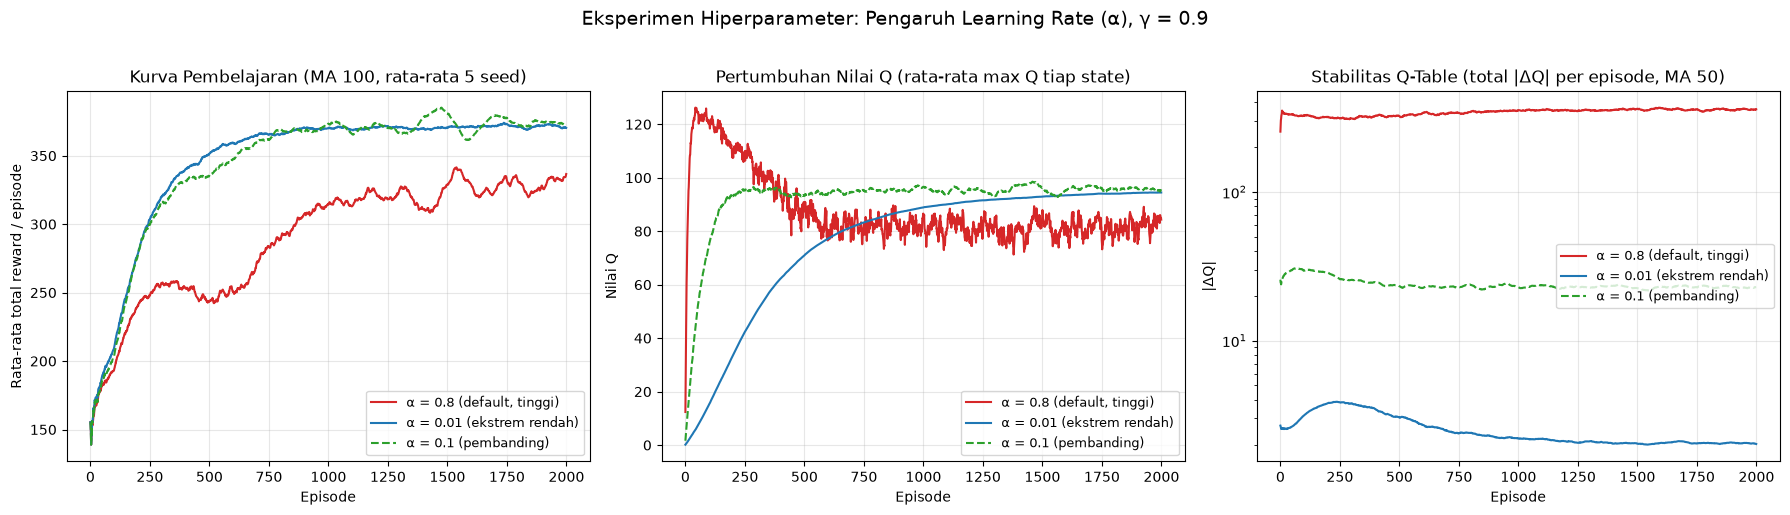

In [ ]:
ALPHAS = {"α = 0.8 (default, tinggi)": 0.8,
          "α = 0.01 (ekstrem rendah)": 0.01,
          "α = 0.1 (pembanding)": 0.1}
COLORS = {0.8: "#d62728", 0.01: "#1f77b4", 0.1: "#2ca02c"}
SEEDS = [0, 1, 2, 3, 4]
GAMMA, EPISODES, WINDOW = 0.9, 2000, 100


def policy_string(q_table):
    """Kebijakan 9 state sebagai string, urutan state 0..8 (S=sedikit, B=banyak, -=tidak pesan)."""
    return "".join(ACTION_SYMBOLS[a] for a in q_table.argmax(axis=1))


def run_experiment(alphas=ALPHAS, seeds=SEEDS, episodes=EPISODES, gamma=GAMMA):
    results = {}
    for label, alpha in alphas.items():
        runs = []
        for seed in seeds:
            q, hist = train_q_learning(alpha=alpha, gamma=gamma, episodes=episodes, seed=seed)
            ev = evaluate_policy(lambda s, q=q: int(np.argmax(q[s])), n_episodes=300)
            runs.append({"seed": seed, "q": q, "hist": hist, "eval": ev, "policy": policy_string(q)})
        results[label] = {"alpha": alpha, "runs": runs}
    return results


def summarize(results, window=WINDOW):
    rows, pol_rows = [], []
    for label, res in results.items():
        rewards = np.array([r["hist"]["rewards"] for r in res["runs"]])
        ma = pd.Series(rewards.mean(axis=0)).rolling(window, min_periods=1).mean()
        last = rewards[:, -500:]
        policies = [r["policy"] for r in res["runs"]]
        rows.append({
            "Konfigurasi": label,
            "MA reward ep-200": ma.iloc[199],
            "MA reward ep-500": ma.iloc[499],
            "MA reward akhir": ma.iloc[-1],
            "Std reward 500 ep terakhir": last.std(axis=1).mean(),
            "Reward evaluasi greedy (rata2)": np.mean([r["eval"]["Rata-rata reward/episode"] for r in res["runs"]]),
            "Reward evaluasi greedy (std antar seed)": np.std([r["eval"]["Rata-rata reward/episode"] for r in res["runs"]]),
            "Rata2 max Q akhir": np.mean([r["hist"]["q_mean"][-1] for r in res["runs"]]),
            "Jumlah kebijakan unik (dari 5 seed)": len(set(policies)),
        })
        for r in res["runs"]:
            pol_rows.append({"Konfigurasi": label, "seed": r["seed"], "Kebijakan (state 0-8)": r["policy"],
                             "Reward evaluasi": r["eval"]["Rata-rata reward/episode"]})
    return pd.DataFrame(rows).round(2), pd.DataFrame(pol_rows).round(1)


def plot_experiment(results, window=WINDOW, save_path=None):
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    for label, res in results.items():
        a, c = res["alpha"], COLORS.get(res["alpha"], None)
        rewards = np.array([r["hist"]["rewards"] for r in res["runs"]])
        qmean = np.array([r["hist"]["q_mean"] for r in res["runs"]])
        qchg = np.array([r["hist"]["q_change"] for r in res["runs"]])
        style = "--" if a == 0.1 else "-"
        axes[0].plot(pd.Series(rewards.mean(0)).rolling(window, min_periods=1).mean(), style, color=c, label=label)
        axes[1].plot(qmean.mean(0), style, color=c, label=label)
        axes[2].plot(pd.Series(qchg.mean(0)).rolling(50, min_periods=1).mean(), style, color=c, label=label)

    axes[0].set_title(f"Kurva Pembelajaran (MA {window}, rata-rata 5 seed)")
    axes[0].set_xlabel("Episode"); axes[0].set_ylabel("Rata-rata total reward / episode")
    axes[1].set_title("Pertumbuhan Nilai Q (rata-rata max Q tiap state)")
    axes[1].set_xlabel("Episode"); axes[1].set_ylabel("Nilai Q")
    axes[2].set_title("Stabilitas Q-Table (total |ΔQ| per episode, MA 50)")
    axes[2].set_xlabel("Episode"); axes[2].set_ylabel("|ΔQ|"); axes[2].set_yscale("log")
    for ax in axes:
        ax.grid(True, alpha=0.3)
    axes[0].legend(fontsize=9, loc="lower right"); axes[1].legend(fontsize=9, loc="lower right"); axes[2].legend(fontsize=9, loc="center right")
    fig.suptitle("Eksperimen Hiperparameter: Pengaruh Learning Rate (α), γ = 0.9", fontsize=14, y=1.02)
    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
    return fig



exp_results = run_experiment()
exp_summary, exp_policies = summarize(exp_results)
display(exp_summary.set_index("Konfigurasi").T)
plot_experiment(exp_results, save_path="figures/eksperimen_alpha.png")
exp_summary.to_csv("results/eksperimen_alpha_ringkasan.csv", index=False)
exp_policies.to_csv("results/eksperimen_alpha_kebijakan.csv", index=False)

In [11]:
print("Kebijakan hasil tiap seed (S = Sedikit, B = Banyak, - = Tidak; state 0..8):")
print("Acuan exhaustive :", "".join(ACTION_SYMBOLS[a] for a in ref_policy))
display(exp_policies)

Kebijakan hasil tiap seed (S = Sedikit, B = Banyak, - = Tidak; state 0..8):
Acuan exhaustive : SBBSSB--S


,Konfigurasi,seed,Kebijakan (state 0-8),Reward evaluasi
0,"α = 0.8 (default, tinggi)",0,BBBSSB--S,394.4
1,"α = 0.8 (default, tinggi)",1,BBB-SB--B,389.8
2,"α = 0.8 (default, tinggi)",2,SBBBSB-BS,357.5
3,"α = 0.8 (default, tinggi)",3,BBBSBS--S,351.5
4,"α = 0.8 (default, tinggi)",4,BBB-SB--S,390.0
5,α = 0.01 (ekstrem rendah),0,SBB-SS--B,347.8
6,α = 0.01 (ekstrem rendah),1,BBBSSB---,392.2
7,α = 0.01 (ekstrem rendah),2,BBBSSB---,392.2
8,α = 0.01 (ekstrem rendah),3,BBB-SS-B-,360.4
9,α = 0.01 (ekstrem rendah),4,BBB-SS--S,361.5


### Analisis Eksperimen Learning Rate (α)

| Indikator (rata-rata 5 seed) | α = 0.8 (default) | α = 0.01 (ekstrem) | α = 0.1 |
|---|---|---|---|
| MA reward episode 200 / 500 | 240,6 / 243,3 | 278,2 / 351,1 | 277,1 / 335,2 |
| MA reward akhir | 336,6 | 370,4 | **372,8** |
| Std reward 500 episode akhir | 61,2 | **25,4** | 34,0 |
| Reward evaluasi greedy | 376,7 ± 18,3 | 370,8 ± 18,1 | **382,7 ± 7,3** |
| Total \|ΔQ\| per episode (akhir) | ±350 | ±2 | ±22 |

**1. α tinggi (0.8): Q-Table tidak stabil.**
- Panel *Pertumbuhan Nilai Q* menunjukkan nilai Q melonjak ke ±125 dalam ±50 episode (*overshoot*), lalu turun dan terus berosilasi di 75–90 tanpa pernah tenang.
- Panel *Stabilitas* menunjukkan total perubahan Q per episode tetap ±350 sampai akhir. Q-Table **tidak pernah berhenti berubah**.
- Karena permintaan acak, setiap pembaruan menimpa nilai lama dengan satu sampel terbaru. Kebijakan pun berganti-ganti: kelima seed menghasilkan 5 kebijakan berbeda, dan kurva reward-nya paling rendah serta paling bergejolak.

**2. α sangat rendah (0.01): pembelajaran lambat.**
- Nilai Q naik sangat perlahan dan baru mendekati nilai stabil (±93) setelah ±1500 episode, sedangkan α = 0,1 sudah mencapainya dalam ±200 episode. Inilah wujud "pembelajaran lambat".
- Menariknya, kurva reward α = 0,01 tidak tampak lambat. Agen hanya perlu tahu **urutan** nilai Q (aksi mana yang terbesar), bukan nilai Q yang persis. Di state yang sering dikunjungi, urutan itu sudah benar sejak awal karena perbedaan reward langsung antar-aksi cukup besar.
- Kelemahannya muncul di state yang **jarang dikunjungi** (Stok Tinggi). Nilai Q di sana hampir tidak berubah, sehingga kebijakannya masih acak-acakan. Contohnya seed 0 (`SBB-SS--B`, 347,8) dan seed 3 (`BBB-SS-B-`, 360,4). Akibatnya, variasi antar-seed tetap besar (± 18,1).

**3. α menengah (0.1) adalah kompromi terbaik.** Konfigurasi ini memberi reward evaluasi tertinggi (382,7) dan **variasi antar-seed terkecil** (± 7,3). Nilai Q cukup cepat stabil, tetapi pembaruannya tidak terombang-ambing oleh satu sampel.

**Kaitan dengan teori.** Q-Learning dijamin konvergen pada lingkungan stokastik hanya jika learning rate cukup kecil dan menurun seiring waktu, serta semua pasangan state–aksi dikunjungi berulang kali (Watkins & Dayan, 1992). α = 0,8 melanggar syarat pertama, sedangkan α = 0,01 secara praktis tidak cukup mengunjungi state langka dalam 2000 episode. Hasil eksperimen ini konsisten dengan teori tersebut.

## Langkah 6 — Model Final

Berdasarkan Langkah 5, model final memakai **α = 0.1** karena paling stabil. Peluruhan ε juga diperlambat (**decay = 0.002**, 3000 episode) agar state yang jarang dikunjungi, seperti *Stok Tinggi*, sempat dieksplorasi lebih lama. Nilai γ tetap 0.9.

,Baseline,Final
Level akhir (rata-rata MA 300 ep terakhir),299.9,375.4
Episode pertama mencapai 95% level akhir,717,1384
Episode sejak MA selalu >= 95% level akhir,1883,2587
Std reward 200 episode awal,78.0,80.9
Std reward 500 episode akhir,70.3,31.7
Reward min / maks 100 episode awal,-15 / 366,-45 / 330


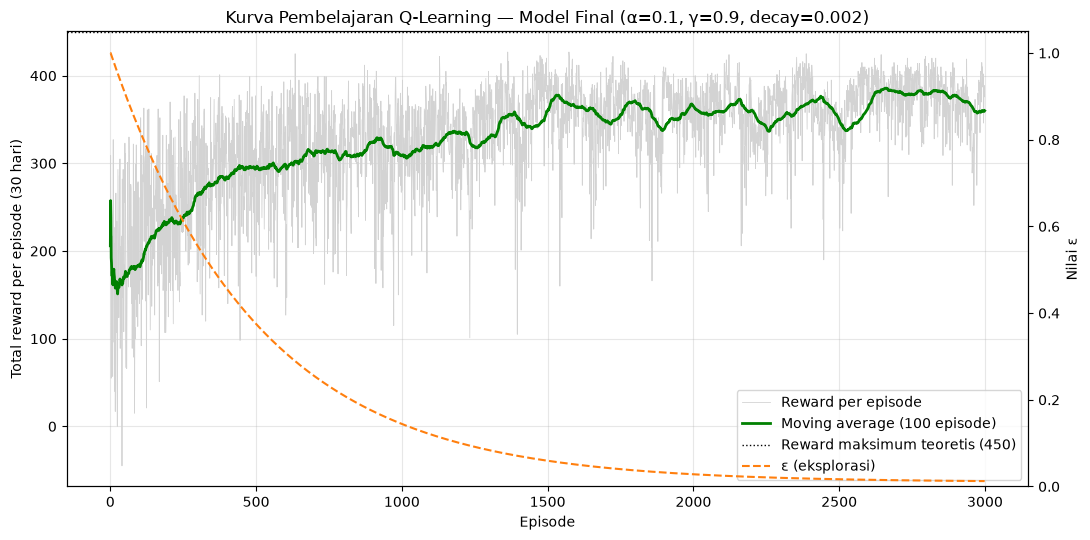

In [12]:
FINAL = dict(BASE, alpha=0.1, decay_rate=0.002, episodes=3000)
q_final, hist_final = train_q_learning(**FINAL)
ma_final = plot_learning_curve(hist_final, "Kurva Pembelajaran Q-Learning — Model Final (α=0.1, γ=0.9, decay=0.002)",
                               "figures/kurva_pembelajaran_final.png")
_, stats_final = convergence_stats(hist_final["rewards"])
display(pd.DataFrame({"Baseline": stats_base, "Final": stats_final}))

,State,Aksi,Kode,Acuan exhaustive,Sama dengan acuan?
0,Stok Rendah | Permintaan Rendah,Pesan Banyak,B,Pesan Sedikit,tidak
1,Stok Rendah | Permintaan Sedang,Pesan Banyak,B,Pesan Banyak,ya
2,Stok Rendah | Permintaan Tinggi,Pesan Banyak,B,Pesan Banyak,ya
3,Stok Sedang | Permintaan Rendah,Tidak Pesan,-,Pesan Sedikit,tidak
4,Stok Sedang | Permintaan Sedang,Pesan Sedikit,S,Pesan Sedikit,ya
5,Stok Sedang | Permintaan Tinggi,Pesan Banyak,B,Pesan Banyak,ya
6,Stok Tinggi | Permintaan Rendah,Tidak Pesan,-,Tidak Pesan,ya
7,Stok Tinggi | Permintaan Sedang,Pesan Sedikit,S,Tidak Pesan,tidak
8,Stok Tinggi | Permintaan Tinggi,Pesan Banyak,B,Pesan Sedikit,tidak


Kebijakan final : BBB-SB-SB (388.7) -> peringkat 21 dari 19683 | 98.5% dari acuan terbaik
Kebijakan baseline: peringkat 277 | 89.1% dari acuan terbaik


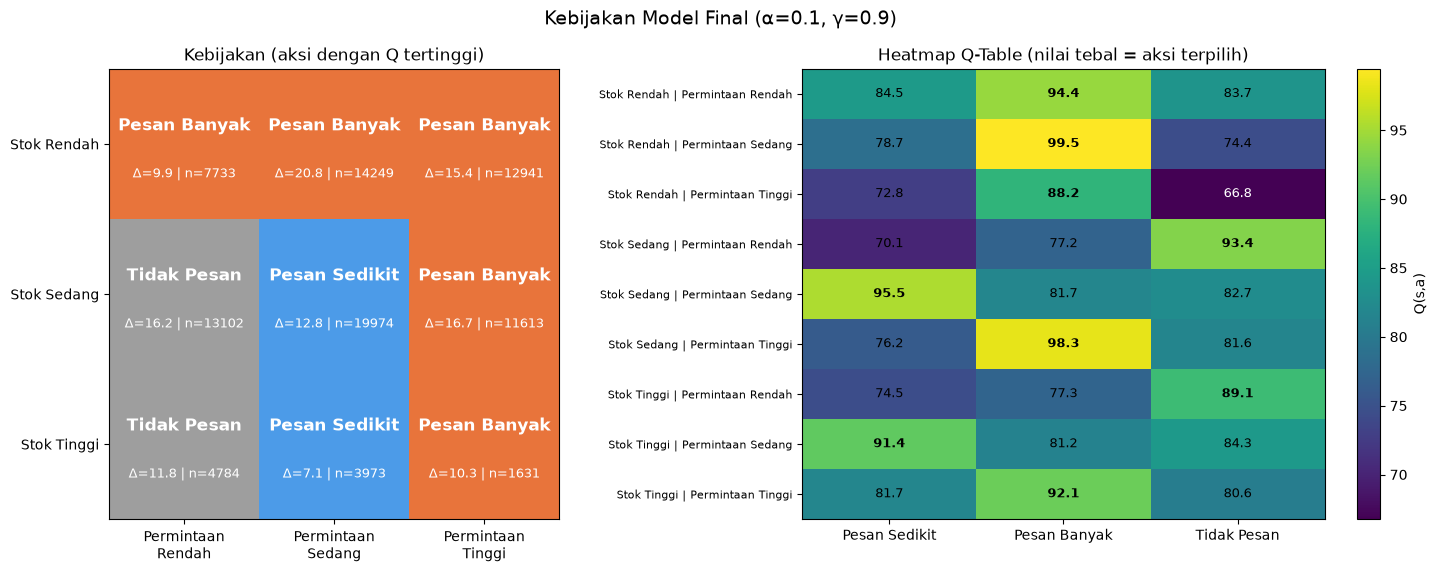

In [13]:
plot_policy(q_final, hist_final["visits"], "Kebijakan Model Final (α=0.1, γ=0.9)", "figures/kebijakan_final.png")
tbl = policy_table(q_final)
tbl["Acuan exhaustive"] = [ACTION_LABELS[a] for a in ref_policy]
tbl["Sama dengan acuan?"] = np.where(q_final.argmax(1) == ref_policy, "ya", "tidak")
display(tbl)
pd.DataFrame(q_final, index=state_index, columns=ACTION_LABELS).to_csv("results/q_table_final.csv")
np.save("results/q_table_final.npy", q_final)
rank_final, score_final = policy_rank(q_final)
print(f"Kebijakan final : {''.join(ACTION_SYMBOLS[a] for a in q_final.argmax(1))} ({score_final:.1f}) "
      f"-> peringkat {rank_final} dari {len(pol_all)} | {100*score_final/mean_all[idx_all[0]]:.1f}% dari acuan terbaik")
print(f"Kebijakan baseline: peringkat {rank_base} | {100*score_base/mean_all[idx_all[0]]:.1f}% dari acuan terbaik")

In [14]:
# Ketahanan model final terhadap seed (8 seed)
robust = []
for sd in [0, 1, 2, 3, 4, 7, 42, 99]:
    q_s, _ = train_q_learning(**dict(FINAL, seed=sd))
    ev = evaluate_policy(lambda s, q_s=q_s: int(np.argmax(q_s[s])), n_episodes=300)
    robust.append({"seed": sd, "Kebijakan": "".join(ACTION_SYMBOLS[a] for a in q_s.argmax(1)),
                   "Reward evaluasi": round(ev["Rata-rata reward/episode"], 1)})
robust = pd.DataFrame(robust)
display(robust)
print(f"Rata-rata ± std: {robust['Reward evaluasi'].mean():.1f} ± {robust['Reward evaluasi'].std(ddof=0):.1f}")

,seed,Kebijakan,Reward evaluasi
0,0,SBBSSB--S,395.2
1,1,BBBSSB--B,394.0
2,2,BBB-SB-BB,388.3
3,3,SBB-SB--B,376.1
4,4,BBB-SB--S,390.0
5,7,SBBSSB--B,394.7
6,42,BBB-SB-SB,388.9
7,99,BBB-SB-SB,388.9


Rata-rata ± std: 389.5 ± 5.7


,Rata-rata reward/episode,Service level (%),Hari stok habis (%),Hari stok ideal (%),Hari penumpukan (%),Penjualan hilang (%)
Q-Learning final (α=0.1),389.3,99.6,0.4,63.4,4.8,0.1
Q-Learning baseline (α=0.8),352.7,99.7,0.3,54.4,30.8,0.1
Acuan exhaustive (terbaik),395.5,99.7,0.3,69.9,8.9,0.1
Acak,164.7,64.8,35.2,22.9,12.7,26.0
Selalu Pesan Sedikit,135.5,59.4,40.6,16.5,7.4,22.6
Selalu Pesan Banyak,305.1,99.8,0.2,49.0,75.1,0.0
Tidak Pernah Pesan,-128.9,4.3,95.7,1.4,0.3,95.1


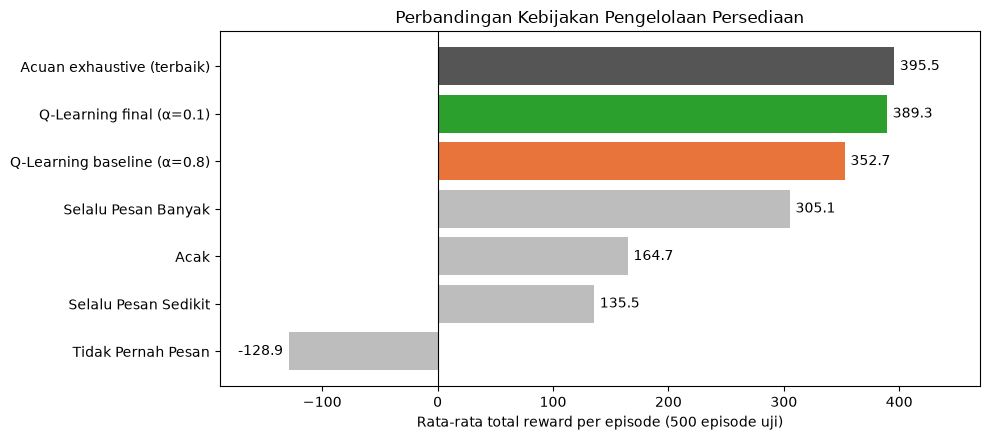

In [15]:
candidates_final = {"Q-Learning final (α=0.1)": lambda s: int(np.argmax(q_final[s]))}
candidates_final.update(candidates)
eval_all = pd.DataFrame({k: evaluate_policy(f, n_episodes=500) for k, f in candidates_final.items()}).T.round(1)
eval_all.to_csv("results/evaluasi_kebijakan.csv")
display(eval_all)

fig, ax = plt.subplots(figsize=(10, 4.5))
order = eval_all["Rata-rata reward/episode"].sort_values()
colors = ["#2ca02c" if "final" in k else "#E8743B" if "baseline" in k else "#555555" if "Acuan" in k else "#BDBDBD" for k in order.index]
ax.barh(order.index, order.values, color=colors)
for y, v in enumerate(order.values):
    ax.text(v + (5 if v >= 0 else -5), y, f"{v:.1f}", va="center", ha="left" if v >= 0 else "right")
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Rata-rata total reward per episode (500 episode uji)")
ax.set_title("Perbandingan Kebijakan Pengelolaan Persediaan")
ax.set_xlim(order.min() - 60, 470)
fig.tight_layout(); fig.savefig("figures/perbandingan_kebijakan.png", dpi=150)

Stok awal: 16 unit | Total reward: 404 | Hari terlayani penuh: 30/30 | Hari stok ideal: 22/30


,Hari,Stok awal,Kategori stok,Tingkat permintaan,Aksi,Pesan (unit),Permintaan,Terjual,Stok akhir,Reward
0,1,16,Tinggi,Sedang,Pesan Sedikit,5,7,7,13,12
1,2,13,Sedang,Rendah,Tidak Pesan,0,3,3,10,15
2,3,10,Sedang,Rendah,Tidak Pesan,0,3,3,7,15
3,4,7,Sedang,Rendah,Tidak Pesan,0,4,4,3,10
4,5,3,Rendah,Rendah,Pesan Banyak,10,4,4,9,15
5,6,9,Sedang,Sedang,Pesan Sedikit,5,8,8,6,10
6,7,6,Rendah,Sedang,Pesan Banyak,10,5,5,11,15
7,8,11,Sedang,Sedang,Pesan Sedikit,5,7,7,9,15
8,9,9,Sedang,Sedang,Pesan Sedikit,5,8,8,6,10
9,10,6,Rendah,Sedang,Pesan Banyak,10,5,5,11,15


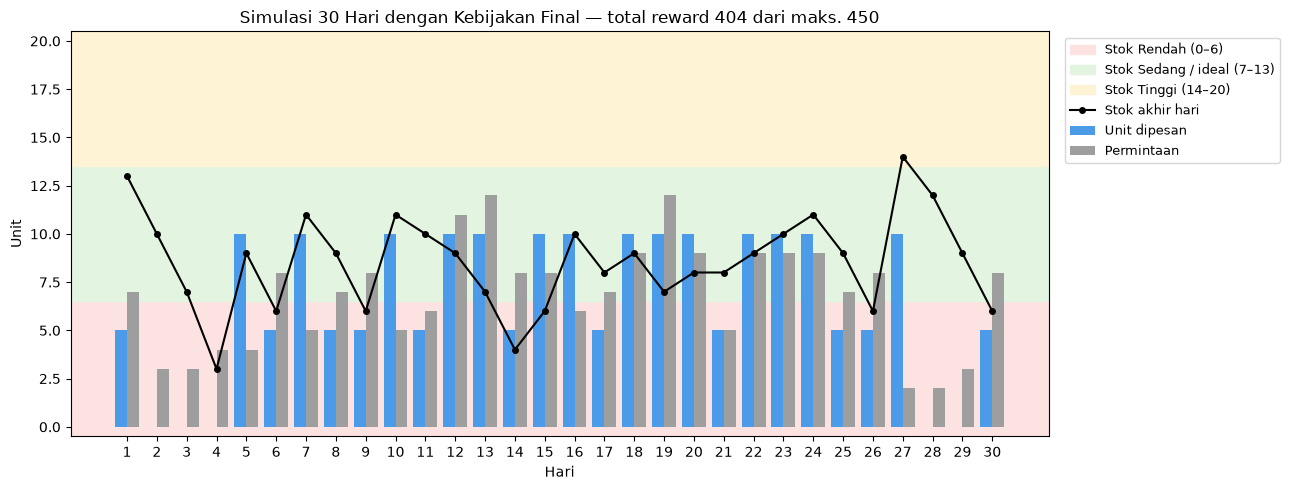

In [16]:
# Simulasi 30 hari memakai kebijakan final (demonstrasi operasional)
sim_env = MinimarketInventoryEnv(seed=11)
state = sim_env.reset()
start_stock = sim_env.stock
rows = []
done = False
while not done:
    a = int(np.argmax(q_final[state]))
    s_cat, d_cat = MinimarketInventoryEnv.decode(state)
    before = sim_env.stock
    state, r, done, info = sim_env.step(a)
    rows.append({"Hari": sim_env.day, "Stok awal": before, "Kategori stok": STOCK_LABELS[s_cat],
                 "Tingkat permintaan": DEMAND_LABELS[d_cat], "Aksi": ACTION_LABELS[a], "Pesan (unit)": info["order"],
                 "Permintaan": info["demand"], "Terjual": info["sold"], "Stok akhir": info["stock_units"], "Reward": r})
sim = pd.DataFrame(rows)
sim.to_csv("results/simulasi_30_hari.csv", index=False)

fig, ax = plt.subplots(figsize=(13, 5))
ax.axhspan(-0.5, 6.5, color="#FDE2E2", label="Stok Rendah (0–6)")
ax.axhspan(6.5, 13.5, color="#E3F4E1", label="Stok Sedang / ideal (7–13)")
ax.axhspan(13.5, 20.5, color="#FFF3D6", label="Stok Tinggi (14–20)")
ax.bar(sim["Hari"] - 0.2, sim["Pesan (unit)"], width=0.4, color="#4C9BE8", label="Unit dipesan")
ax.bar(sim["Hari"] + 0.2, sim["Permintaan"], width=0.4, color="#9E9E9E", label="Permintaan")
ax.plot(sim["Hari"], sim["Stok akhir"], "k-o", ms=4, label="Stok akhir hari")
ax.set_xlabel("Hari"); ax.set_ylabel("Unit"); ax.set_ylim(-0.5, 20.5); ax.set_xticks(range(1, 31))
ax.set_title(f"Simulasi 30 Hari dengan Kebijakan Final — total reward {sim['Reward'].sum()} dari maks. 450")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9)
fig.tight_layout(); fig.savefig("figures/simulasi_30_hari.png", dpi=150)
print(f"Stok awal: {start_stock} unit | Total reward: {sim['Reward'].sum()} | "
      f"Hari terlayani penuh: {(sim['Terjual'] == sim['Permintaan']).sum()}/30 | "
      f"Hari stok ideal: {(sim['Stok akhir'].between(7, 13)).sum()}/30")
display(sim.head(10))

### Analisis Model Final

**Kurva pembelajaran.** Level akhir naik dari **299,9 (baseline) menjadi 375,4**. Fluktuasi akhir turun lebih dari separuh: standar deviasi 500 episode terakhir **70,3 → 31,7**. MA pertama kali mencapai 95% level akhir pada episode ±1384. Waktu ini lebih lama dari baseline karena ε diturunkan lebih pelan (ε < 0,05 baru tercapai sekitar episode 1600). Itu disengaja, agar state yang jarang muncul sempat dieksplorasi. Sisa fluktuasi ±5% berasal dari keacakan permintaan, bukan dari Q-Table yang berubah-ubah.

**Kebijakan final (`BBB-SB-SB`) dan logika agen:**
- **Stok Rendah → Pesan Banyak** pada semua tingkat permintaan: segera pulihkan stok agar tidak kehabisan.
- **Stok Sedang:** permintaan rendah → *Tidak Pesan*, permintaan sedang → *Pesan Sedikit*, permintaan tinggi → *Pesan Banyak*. Ini perilaku yang paling "manusiawi", yaitu jumlah pesanan disesuaikan dengan perkiraan penjualan.
- **Stok Tinggi – Permintaan Rendah → Tidak Pesan:** habiskan dulu stok yang menumpuk. Kesalahan baseline di state ini sudah hilang.
- Ada empat state yang berbeda dari acuan (`SBBSSB--S`), tetapi semuanya berdampak kecil:
  - **Stok Rendah – Permintaan Rendah**: Banyak vs Sedikit memang hampir setara (394,5 vs 394,6).
  - **Stok Sedang – Permintaan Rendah**: *Tidak Pesan* vs *Pesan Sedikit*. Keduanya masuk akal. Acuan sedikit lebih baik karena stok bertahan lebih lama di zona ideal.
  - **Stok Tinggi – Permintaan Sedang** (*Pesan Sedikit*, Δ = 7,1, paling ragu) dan **Stok Tinggi – Permintaan Tinggi**: keduanya paling jarang dikunjungi (n = 3973 dan 1631). Efeknya terlihat pada hari ke-1 simulasi: stok 16 + 5 unit meluap sehingga reward hanya 12.

**Kualitas terhadap optimum.** Kebijakan final berada di **peringkat 21 dari 19.683** kemungkinan kebijakan (0,1% teratas), dengan skor ±98,5% dari kebijakan terbaik. Baseline berada di peringkat 277. Pada 8 seed berbeda, hasilnya **389,5 ± 5,7** dan seluruhnya memiliki struktur kebijakan yang sama.

**Dampak operasional (500 episode uji):**

| Kebijakan | Reward | Service level | Hari stok ideal | Hari penumpukan |
|---|---|---|---|---|
| Q-Learning final | **389,3** | 99,6% | 63,4% | **4,8%** |
| Q-Learning baseline | 352,7 | 99,7% | 54,4% | 30,8% |
| Selalu Pesan Banyak | 305,1 | 99,8% | 49,0% | 75,1% |
| Acak | 164,7 | 64,8% | 22,9% | 12,7% |

Agen final menjaga hampir semua permintaan terlayani, sama baiknya dengan "selalu pesan banyak". Bedanya, agen final melakukannya dengan **penumpukan 15 kali lebih jarang**.

**Simulasi 30 hari** menghasilkan reward 404/450, 30/30 hari terlayani penuh, dan 22/30 hari stok ideal. Pada hari 2–4 permintaan rendah, sehingga agen tidak memesan dan membiarkan stok turun dari 13 ke 3. Begitu stok rendah (hari 5), agen memesan banyak. Pada periode permintaan tinggi (hari 18–24), agen memesan banyak setiap hari dan stok tetap di 7–11. Hari ke-27 memperlihatkan efek *state aliasing*: stok 6 tergolong "Rendah", sehingga agen memesan banyak dan stok akhir menjadi 14 (penumpukan).

## Kesimpulan

1. Rancangan TP-07 (9 state, 3 aksi, reward +10/+5/−5/−3) berhasil diimplementasikan sebagai lingkungan simulasi minimarket. Q-Learning mampu mempelajari kebijakan persediaan tanpa data berlabel. Kebijakan akhirnya mengungguli semua kebijakan sederhana dan mencapai ±98% dari kebijakan optimal hasil pencarian exhaustive.
2. Kebijakan yang dipelajari logis dan dapat dijelaskan: **pesan banyak saat stok rendah, sesuaikan jumlah pesanan dengan permintaan saat stok sedang, dan tahan pemesanan saat stok tinggi**.
3. Pada lingkungan stokastik, **learning rate adalah hiperparameter paling kritis**. α = 0,8 membuat Q-Table tidak stabil dan kebijakan berubah-ubah. α = 0,01 stabil tetapi lambat dan kurang terlatih di state langka. α = 0,1 memberi hasil terbaik dan paling konsisten.
4. Peluruhan ε yang lebih lambat membantu agen mengeksplorasi state yang jarang dikunjungi.

### Keterbatasan dan saran pengembangan
- **State aliasing:** tiga kategori stok terlalu kasar (stok 0 dan 6 dianggap sama). Kategori dapat diperhalus, misalnya menjadi 5 level. Harga yang dibayar adalah state space yang membesar, yaitu *curse of dimensionality*.
- **Desain reward:** penalti penumpukan (−3) jauh lebih kecil daripada reward terpenuhi (+10), sehingga kelebihan stok relatif "murah". Itu sebabnya "selalu pesan banyak" masih memperoleh 305. Untuk kasus nyata, perlu ditambahkan biaya simpan, biaya pemesanan, atau risiko kedaluwarsa.
- **Realisme:** belum ada *lead time* pengiriman, variasi hari (hari kerja vs akhir pekan), maupun banyak jenis barang. Bila state bertambah besar, Q-Table dapat digantikan oleh *Deep Q-Network* (DQN).
- **Learning rate menurun** (misalnya α = 1/jumlah kunjungan) dapat dicoba agar konvergensi lebih terjamin secara teoretis.

### Referensi
- Sutton, R. S., & Barto, A. G. (2018). *Reinforcement Learning: An Introduction* (2nd ed.). MIT Press.
- Watkins, C. J. C. H., & Dayan, P. (1992). Q-learning. *Machine Learning*, 8(3–4), 279–292.